In [43]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/boshramahbub/ecomerce-customer-behaviour-dataset/ecommerce_customer_behavior_dataset (1).csv
/kaggle/input/datasets/boshramahbub/lab-3-cleaned-ecom/new_cleaned_dataset_Ecommerce.csv


# Task 1: Load Your Dataset

In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df=pd.read_csv("/kaggle/input/datasets/boshramahbub/lab-3-cleaned-ecom/new_cleaned_dataset_Ecommerce.csv")

df.head()


,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,2023-01-01,0.157895,Female,Bursa,Toys,0.006863,0.0,0.000000,0.002108,Debit Card,Mobile,0.041667,0.565217,True,0.291667,5
1,2023-01-01,0.421053,Male,Konya,Toys,0.033507,0.0,0.000000,0.010766,Credit Card,Mobile,0.138889,0.086957,True,0.083333,3
2,2023-01-01,0.438596,Female,Ankara,Food,0.006006,1.0,0.000000,0.010578,Credit Card,Mobile,0.083333,0.304348,True,0.166667,2
3,2023-01-01,0.245614,Male,Istanbul,Electronics,0.111665,0.0,0.150293,0.025750,Credit Card,Mobile,0.097222,0.391304,False,0.000000,4
4,2023-01-01,0.385965,Female,Istanbul,Sports,0.104893,1.0,0.000000,0.171247,Cash on Delivery,Desktop,0.277778,0.391304,True,0.250000,4


In [85]:
print("Shape:",df.shape)
print("\nNumerical Attributes:")
print(df.select_dtypes(include=np.number).columns)

print("\nCategorical Attributes:")
print(df.select_dtypes(include="object").columns)



Shape: (5000, 16)

Numerical Attributes:
Index(['Age', 'Unit_Price', 'Quantity', 'Discount_Amount', 'Total_Amount',
       'Session_Duration_Minutes', 'Pages_Viewed', 'Delivery_Time_Days',
       'Customer_Rating'],
      dtype='object')

Categorical Attributes:
Index(['Date', 'Gender', 'City', 'Product_Category', 'Payment_Method',
       'Device_Type'],
      dtype='object')


# Task 2: Select Numerical Attributes

In [86]:
numeric_cols=["Unit_Price", "Quantity"]
data = df[numeric_cols].dropna()

data.head()


,Unit_Price,Quantity
0,0.006863,0.0
1,0.033507,0.0
2,0.006006,1.0
3,0.111665,0.0
4,0.104893,1.0


In [87]:
selected_attributes = pd.DataFrame({
    "Attribute": ["Unit_Price", "Quantity"],
    "Type": ["Numerical", "Numerical"],
    "Why selected?": [
        "Meaningful measurement of product price",
        "Meaningful measurement of units purchased"
    ]
})

selected_attributes

,Attribute,Type,Why selected?
0,Unit_Price,Numerical,Meaningful measurement of product price
1,Quantity,Numerical,Meaningful measurement of units purchased


# Task 3: Select Two Data Objects

In [88]:
A = df[['Age', 'Unit_Price', 'Quantity', 'Discount_Amount',
        'Total_Amount', 'Session_Duration_Minutes', 'Pages_Viewed',
        'Delivery_Time_Days', 'Customer_Rating']].iloc[0].values

B = df[['Age', 'Unit_Price', 'Quantity', 'Discount_Amount',
        'Total_Amount', 'Session_Duration_Minutes', 'Pages_Viewed',
        'Delivery_Time_Days', 'Customer_Rating']].iloc[1].values

print("A =", A)
print("B =", B)

A = [1.57894737e-01 6.86303424e-03 0.00000000e+00 0.00000000e+00
 2.10800948e-03 4.16666667e-02 5.65217391e-01 2.91666667e-01
 5.00000000e+00]
B = [0.42105263 0.03350726 0.         0.         0.01076625 0.13888889
 0.08695652 0.08333333 3.        ]


# Task 4: Calculate Euclidean Distance

In [89]:
from scipy.spatial.distance import euclidean

distance = euclidean(A, B)

print("Euclidean Distance:", distance)


Euclidean Distance: 2.0860549741396244


1.Is the distance small or large?
 ANS:The Euclidean distance is 2.086, it's relatively large because the normalization range was between 0 to 1 . 
2.What does this indicate about the two objects?
 ANS:indicates that the two objects are relatively dissimilar
3.Which attribute contributes more to the distance?
ANS:Customer rating


# Task 5: Calculate Manhattan Distance

In [90]:
from scipy.spatial.distance import cityblock

manhattan_distance = cityblock(A, B)

print("Manhattan Distance:", manhattan_distance)


Manhattan Distance: 3.0822767844587577


1.What is the Manhattan distance?
ANS:ANS:Manhattan distance is a metric that measures the distance
between two points by adding the absolute differences of their coordinates.

2.Is it larger or smaller than Euclidean distance?
ANS: larger than Euclidean distance
3.Why can Manhattan distance be useful for some datasets?
ANS: Manhattan distance be useful for some datasets where the total absolute difference between datas are important.


# Task 6: Calculate Minkowski Distance

In [91]:
from scipy.spatial.distance import minkowski

for q in [1, 2, 3, 5]:
    d = minkowski(A, B, p=q)
    print("q =", q, "Distance =", d)

q = 1 Distance = 3.0822767844587577
q = 2 Distance = 2.0860549741396244
q = 3 Distance = 2.0114014848715898
q = 5 Distance = 2.0003334556925654


In [92]:


# Required table
minkowski_table = pd.DataFrame({
    "q": [1, 2, 3, 5],
    "Minkowski Distance": [minkowski(A, B, p=q) for q in [1, 2, 3, 5]]
})
print(minkowski_table)

# What happens for a very large q?
print("\nq = 50 ->", minkowski(A, B, p=50))


   q  Minkowski Distance
0  1            3.082277
1  2            2.086055
2  3            2.011401
3  5            2.000333

q = 50 -> 2.0


**Required table**

| q | Minkowski Distance |
|---|---|
| 1 | 3.0823 |
| 2 | 2.0861 |
| 3 | 2.0114 |
| 5 | 2.0003 |

**1. What happens when q = 1?**
ANS: Minkowski distance becomes the Manhattan distance (3.0823), the sum of the absolute differences of all attributes.

**2. What happens when q = 2?**
ANS: It becomes the Euclidean distance (2.0861), the straight-line distance.

**3. How does the distance change as q increases?**
ANS: The distance becomes smaller (3.0823 -> 2.0861 -> 2.0114 -> 2.0003) and gets closer and closer to the largest single attribute difference. For a very large q (q = 50) it is 2.0, which is the Chebyshev distance.

**4. Why is Minkowski considered a generalized distance?**
ANS: Because one formula, (sum of |x - y|^q)^(1/q), gives the other distances just by changing q: q = 1 is Manhattan, q = 2 is Euclidean, and a very large q approaches Chebyshev.

# Task 7: Calculate Chebyshev Distance

In [93]:
from scipy.spatial.distance import chebyshev

cheb_distance = chebyshev(A, B)

print("Chebyshev Distance:", cheb_distance)


Chebyshev Distance: 2.0


In [54]:
# Difference of every attribute between A and B
columns = ['Age', 'Unit_Price', 'Quantity', 'Discount_Amount',
           'Total_Amount', 'Session_Duration_Minutes', 'Pages_Viewed',
           'Delivery_Time_Days', 'Customer_Rating']

differences = abs(A - B)

diff_table = pd.DataFrame({"Attribute": columns, "|A - B|": differences})
print(diff_table)
print("\nLargest difference:", max(differences))

                  Attribute   |A - B|
0                       Age  0.263158
1                Unit_Price  0.026644
2                  Quantity  0.000000
3           Discount_Amount  0.000000
4              Total_Amount  0.008658
5  Session_Duration_Minutes  0.097222
6              Pages_Viewed  0.478261
7        Delivery_Time_Days  0.208333
8           Customer_Rating  2.000000

Largest difference: 2.0


**1. Which attribute produced the maximum difference?**
ANS: **Customer_Rating**. Its difference is |5 - 3| = 2.0, while every other attribute differs by less than 0.5 (the next largest is Pages_Viewed with 0.478). Unit_Price differs by only about 0.027.

**2. What is the Chebyshev distance?**
ANS: 2.0, which is the largest absolute difference among all attributes (the Customer_Rating difference).

**3. How is it different from Euclidean distance?**
ANS: Euclidean distance (2.0861) combines the squared differences of *all* attributes, while Chebyshev distance uses only the *single largest* difference and ignores the rest. Here they are almost equal because Customer_Rating (still on a 1-5 scale, not normalized) is much bigger than all other differences and dominates both measures.

# Task 8: Distance Comparison

In [55]:
results = {
    "Euclidean": euclidean(A, B),
    "Manhattan": cityblock(A, B),
    "Minkowski (q=3)": minkowski(A, B, p=3),
    "Chebyshev": chebyshev(A, B)
}

results

{'Euclidean': 2.0860549741396244,
 'Manhattan': np.float64(3.0822767844587577),
 'Minkowski (q=3)': np.float64(2.0114014848715898),
 'Chebyshev': np.float64(2.0)}

In [56]:
# Required table
results_table = pd.DataFrame({
    "Distance Measure": list(results.keys()),
    "Value": list(results.values())
})
results_table

,Distance Measure,Value
0,Euclidean,2.086055
1,Manhattan,3.082277
2,Minkowski (q=3),2.011401
3,Chebyshev,2.000000


**Required table**

| Distance Measure | Value |
|---|---|
| Euclidean | 2.0861 |
| Manhattan | 3.0823 |
| Minkowski q=3 | 2.0114 |
| Chebyshev | 2.0000 |

**Discussion**

**1. Which measure produced the largest value?**
ANS: Manhattan distance (3.0823), because it adds up all the absolute differences.

**2. Which produced the smallest value?**
ANS: Chebyshev distance (2.0), because it keeps only the largest difference. The order is Manhattan > Euclidean > Minkowski (q=3) > Chebyshev.

**3. Can you directly say that one measure is "better" than another?**
ANS: No. They simply measure difference in different ways, so none is best in every situation. The right choice depends on the data and on the problem.

**4. Why might different applications use different distance measures?**
ANS: Manhattan is useful when the total difference over all attributes matters (e.g. movement along city blocks, or many attributes). Euclidean is used when the real straight-line distance matters (e.g. locations). Chebyshev is useful when the worst single attribute decides the difference (e.g. one measurement out of tolerance makes the item unacceptable).

# Task 9: Investigate the Effect of Normalization

In [57]:
df_before=pd.read_csv("/kaggle/input/datasets/boshramahbub/ecomerce-customer-behaviour-dataset/ecommerce_customer_behavior_dataset (1).csv")
print(df_before)

        Order_ID Customer_ID        Date  Age  Gender      City  \
0     ORD_001337  CUST_01337  2023-01-01   27  Female     Bursa   
1     ORD_004885  CUST_04885  2023-01-01   42    Male     Konya   
2     ORD_004507  CUST_04507  2023-01-01   43  Female    Ankara   
3     ORD_000645  CUST_00645  2023-01-01   32    Male  Istanbul   
4     ORD_000690  CUST_00690  2023-01-01   40  Female  Istanbul   
...          ...         ...         ...  ...     ...       ...   
4995  ORD_001048  CUST_01048  2024-03-26   18  Female     Izmir   
4996  ORD_001051  CUST_01051  2024-03-26   27    Male     Adana   
4997  ORD_003543  CUST_03543  2024-03-26   45  Female   Antalya   
4998  ORD_004443  CUST_04443  2024-03-26   41  Female  Istanbul   
4999  ORD_000902  CUST_00902  2024-03-26   30  Female     Konya   

     Product_Category  Unit_Price  Quantity  Discount_Amount  Total_Amount  \
0                Toys       54.28         1             0.00         54.28   
1                Toys      244.90      

In [58]:
# Before normalization
numeric_cols = df_before.select_dtypes(include=np.number).columns

A_original = df_before[numeric_cols].iloc[0].values
B_original = df_before[numeric_cols].iloc[1].values

euclidean(A_original, B_original)

270.3626616232352

In [59]:
# After normalization
numeric_cols=df.select_dtypes(include=np.number).columns
A = df[numeric_cols].iloc[0].values

B = df[numeric_cols].iloc[1].values

euclidean(A,B)


2.0860549741396244

In [60]:
# Required Output
Selected_Output=pd.DataFrame({
"Condition": ["Before Normalization","After Normalization"],
"Eucledian distance":[270.3626616232352,2.0860549741396244]


    
})
print(Selected_Output)

              Condition  Eucledian distance
0  Before Normalization          270.362662
1   After Normalization            2.086055


1.Did the distance changed?
ANS:Yes, significantly.
It decreased from 270.36 to 2.086 after normalization.
2.Why?
  ANS:Because normalization puts the numerical attributes onto a similar scale.
3.Why is normalization important before some distance-based algorithms?
ANS: It is important for distance-based algorithms because it allows attributes to contribute more fairly.
4.Does normalization change the identity of the objects?
ANS: no

# Task 10: Categorical Similarity

In [61]:
categorical_cols = df.select_dtypes(
    include=['object', 'category']
).columns

print("Categorical Attributes:", categorical_cols)

Categorical Attributes: Index(['Date', 'Gender', 'City', 'Product_Category', 'Payment_Method',
       'Device_Type'],
      dtype='object')


In [62]:

# Task 10: Categorical Similarity

categorical_cols = [
    'Gender',
    'City',
    'Product_Category',
    'Payment_Method',
    'Device_Type'
]

# Select two records from your dataset
A = df.loc[0, categorical_cols].tolist()
B = df.loc[1, categorical_cols].tolist()

matches = sum(a == b for a, b in zip(A, B))
total = len(categorical_cols)
different = total - matches

similarity = matches / total

print("Number of matching attributes =", matches)
print("Number of differing attributes =", different)
print("Total attributes =", total)
print("Similarity =", round(similarity, 4))
print("Percentage similar =", round(similarity * 100, 2), "%")


Number of matching attributes = 2
Number of differing attributes = 3
Total attributes = 5
Similarity = 0.4
Percentage similar = 40.0 %


1. How many attributes differed?
ANS: 3 attributes differed.
2. What percentage of attributes are similar?
ANS:40%, because \(\frac{2}{5}\times100=40\%\).
3. Is this approach meaningful for categorical data?
ANS:Yes. Simple Matching Similarity is meaningful for categorical data because it compares values directly and counts how many attributes match. It does not require numerical measurements or Euclidean distance. However, it treats all attributes as equally important.

# Task 11: Binary Similarity

In [63]:
A = np.array([1, 1, 0, 1, 0])
B = np.array([1, 0, 0, 1, 1])

print("Matching 1s:", np.sum((A == 1) & (B == 1)))
print("Matching 0s:", np.sum((A == 0) & (B == 0)))
print("Mismatches:", np.sum(A != B))

Matching 1s: 2
Matching 0s: 1
Mismatches: 2


In [64]:
# Extra: turn the counts into similarity values
matching_1s = np.sum((A == 1) & (B == 1))
matching_0s = np.sum((A == 0) & (B == 0))
mismatches = np.sum(A != B)

# Simple Matching Similarity: counts the 0-0 matches too
smc = (matching_1s + matching_0s) / len(A)

# Jaccard Similarity: ignores the 0-0 matches
jaccard = matching_1s / (matching_1s + mismatches)

print("Simple Matching Similarity:", smc)
print("Jaccard Similarity:", jaccard)

Simple Matching Similarity: 0.6
Jaccard Similarity: 0.5


In [65]:
# Two objects that share NO present attribute (only 0-0 matches)
A_sparse = np.array([1, 0, 0, 0, 0, 0, 0, 0, 0, 0])
B_sparse = np.array([0, 1, 0, 0, 0, 0, 0, 0, 0, 0])

ones = np.sum((A_sparse == 1) & (B_sparse == 1))
zeros = np.sum((A_sparse == 0) & (B_sparse == 0))
diff = np.sum(A_sparse != B_sparse)

print("Simple Matching Similarity:", (ones + zeros) / len(A_sparse))
print("Jaccard Similarity:", ones / (ones + diff))

Simple Matching Similarity: 0.8
Jaccard Similarity: 0.0


**Report**

| Quantity | Value |
|---|---|
| Matching 1s | 2 |
| Matching 0s | 1 |
| Mismatches | 2 |
| Simple Matching Coefficient | 3/5 = 0.6 |
| Jaccard Coefficient | 2/4 = 0.5 |

**1. Are matching 0s always meaningful?**
ANS: No. A 0-0 match only says that both objects lack an attribute, which is not always evidence that they are alike. In the last cell above, two objects share *no* present attribute, yet the Simple Matching Coefficient is 0.8 because eight attributes are 0-0 matches, while Jaccard correctly gives 0.

**2. Give an example where the presence of an attribute is more important than its absence.**
ANS: Market-basket data. If two customers both did *not* buy hundreds of items in a store, this says almost nothing about them, but if both bought the same product, that is a real similarity. The same is true for words in a document (a word that is present matters, absent words do not) and for a rare symptom or disease in medical data.

**3. Why might binary similarity require special treatment?**
ANS: Binary attributes can be *symmetric* (both values equally important, e.g. gender) or *asymmetric* (only 1 is important, e.g. a positive test). For symmetric attributes we use the Simple Matching Coefficient, but for asymmetric/sparse attributes the 0-0 matches would inflate the similarity, so we use the Jaccard coefficient, which ignores them.

# Task 12: Cosine Similarity

In [66]:
from sklearn.metrics.pairwise import cosine_similarity

A = np.array([[2, 1, 0]])
B = np.array([[1, 1, 1]])

similarity = cosine_similarity(A, B)

print("Cosine Similarity:", similarity[0][0])

Cosine Similarity: 0.7745966692414834


In [67]:
# Extra check: making a vector 10 times longer does not change the cosine similarity
print("Cosine similarity of A and 10*A:", round(cosine_similarity(A, 10 * A)[0][0], 4))

Cosine similarity of A and 10*A: 1.0


**1. What is the cosine similarity?**
ANS: 0.7746 (about 0.77).

**2. Is the value closer to 0 or 1?**
ANS: It is closer to 1.

**3. What does this tell us about the two vectors?**
ANS: The two vectors point in a fairly similar direction (the angle between them is about 39°), so A and B are quite similar in their pattern of values, although not identical. A value of 1 would mean the same direction and 0 would mean no similarity at all (perpendicular vectors).

**4. Why is cosine similarity particularly useful for text data?**
ANS: Text vectors are very long and sparse, and documents have different lengths. Cosine similarity compares only the *direction* (which words are used and in what proportion) and ignores the vector length, so a long document and a short document on the same topic still get a high similarity (cos(A, 10A) = 1). It is also not inflated by the many shared zeros.

# Task 13: Manual Cosine Similarity

In [68]:
A_m = np.array([2, 1, 0])
B_m = np.array([1, 1, 1])

# Step 1: dot product
dot = (2 * 1) + (1 * 1) + (0 * 1)
print("Step 1: A . B =", dot)

# Step 2: magnitude of A
mag_A = np.sqrt(2**2 + 1**2 + 0**2)
print("Step 2: ||A|| =", mag_A)

# Step 3: magnitude of B
mag_B = np.sqrt(1**2 + 1**2 + 1**2)
print("Step 3: ||B|| =", mag_B)

# Step 4: cosine similarity
cos_manual = dot / (mag_A * mag_B)
print("Step 4: sim(A, B) =", cos_manual)

# Compare with Python
print("Python answer     =", cosine_similarity([A_m], [B_m])[0][0])

Step 1: A . B = 3
Step 2: ||A|| = 2.23606797749979
Step 3: ||B|| = 1.7320508075688772
Step 4: sim(A, B) = 0.7745966692414834
Python answer     = 0.7745966692414834


**Manual solution**

- Step 1: A·B = (2)(1) + (1)(1) + (0)(1) = 2 + 1 + 0 = **3**
- Step 2: ||A|| = √(2² + 1² + 0²) = √5 ≈ **2.2361**
- Step 3: ||B|| = √(1² + 1² + 1²) = √3 ≈ **1.7321**
- Step 4: sim(A, B) = 3 / (√5 × √3) = 3 / √15 ≈ **0.7746**

**Comparison:** the manual answer (0.7746) is exactly the same as the Python (`cosine_similarity`) answer from Task 12.

# Task 14: Create a Small Text Dataset

In [69]:
documents = [
    "data mining finds useful patterns",
    "data mining discovers useful knowledge",
    "machine learning finds useful patterns",
    "students learn data mining"
]

for i, doc in enumerate(documents):
    print("Document", i+1, ":", doc)

Document 1 : data mining finds useful patterns
Document 2 : data mining discovers useful knowledge
Document 3 : machine learning finds useful patterns
Document 4 : students learn data mining


In [70]:
# Extra: vocabulary and in how many documents each word appears
print("Number of documents:", len(documents))

word_count = {}
for doc in documents:
    for word in set(doc.split()):
        word_count[word] = word_count.get(word, 0) + 1

print("Vocabulary:", sorted(word_count))
print("Vocabulary size:", len(word_count))

print("\nWords in multiple documents:")
for word in sorted(word_count):
    if word_count[word] > 1:
        print(" ", word, "->", word_count[word], "documents")

print("\nWords in only one document:")
for word in sorted(word_count):
    if word_count[word] == 1:
        print(" ", word)

Number of documents: 4
Vocabulary: ['data', 'discovers', 'finds', 'knowledge', 'learn', 'learning', 'machine', 'mining', 'patterns', 'students', 'useful']
Vocabulary size: 11

Words in multiple documents:
  data -> 3 documents
  finds -> 2 documents
  mining -> 3 documents
  patterns -> 2 documents
  useful -> 3 documents

Words in only one document:
  discovers
  knowledge
  learn
  learning
  machine
  students


**1. How many documents are there?**
ANS: 4 documents.

**2. What is the vocabulary?**
ANS: 11 unique words: data, discovers, finds, knowledge, learn, learning, machine, mining, patterns, students, useful.

**3. Which words appear in multiple documents?**
ANS: *data* (D1, D2, D4), *mining* (D1, D2, D4), *useful* (D1, D2, D3), *finds* (D1, D3) and *patterns* (D1, D3).

**4. Which words appear only once?**
ANS: *discovers*, *knowledge*, *learn*, *learning*, *machine* and *students* (each in only one document). Note that *learn* and *learning* are counted as two different words because we do not apply stemming.

# Task 15: Create a Term-Frequency Matrix

In [71]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()

X = vectorizer.fit_transform(documents)

tf_matrix = X.toarray()
terms = vectorizer.get_feature_names_out()

tf_df = pd.DataFrame(
    tf_matrix,
    columns=terms,
    index=[f"D{i+1}" for i in range(len(documents))]
)

tf_df

,data,discovers,finds,knowledge,learn,learning,machine,mining,patterns,students,useful
D1,1,0,1,0,0,0,0,1,1,0,1
D2,1,1,0,1,0,0,0,1,0,0,1
D3,0,0,1,0,0,1,1,0,1,0,1
D4,1,0,0,0,1,0,0,1,0,1,0


**1. What does each row represent?**
ANS: One document (D1 to D4).

**2. What does each column represent?**
ANS: One unique term (word) of the vocabulary.

**3. What does a value of 0 mean?**
ANS: The term does not occur in that document.

**4. What does a value of 2 mean?**
ANS: The term occurs twice in that document. In this small dataset no word is repeated inside a document, so all values are 0 or 1, but e.g. "data mining data mining" would give 2 for both *data* and *mining*.

**5. Why does the matrix contain many zeros?**
ANS: Every document uses only a few words from the whole vocabulary, so most terms are absent from most documents. For real text collections with thousands of words, the matrix is extremely sparse.

# Task 16: Term Frequency

In [72]:
chosen_terms = ["data", "mining", "useful"]

tf_table = pd.DataFrame({
    "Document": "D1",
    "Term": chosen_terms,
    "TF": tf_df.loc["D1", chosen_terms].values
})

tf_table

,Document,Term,TF
0,D1,data,1
1,D1,mining,1
2,D1,useful,1


All three chosen terms occur once in D1, so TF = 1 for each of them. Raw TF only tells us how often a word occurs inside one document; it does not tell us whether the word is informative. *data*, *mining* and *useful* each appear in 3 of the 4 documents, which is why we need IDF next.

# Task 17: Inverse Document Frequency

In [73]:
N = len(documents)                      # total number of documents
df_counts = (tf_df > 0).sum()           # in how many documents does each term appear?

chosen_terms = ["data", "patterns", "machine"]

idf_table = pd.DataFrame({
    "Term": chosen_terms,
    "Document Frequency": df_counts[chosen_terms].values,
    "IDF = ln(N/df)": np.log(N / df_counts[chosen_terms].values)
})

idf_table

,Term,Document Frequency,IDF = ln(N/df)
0,data,3,0.287682
1,patterns,2,0.693147
2,machine,1,1.386294


With N = 4 and IDF(t) = ln(N / df(t)):

- *data*: df = 3, IDF = ln(4/3) = **0.2877**
- *patterns*: df = 2, IDF = ln(4/2) = **0.6931**
- *machine*: df = 1, IDF = ln(4/1) = **1.3863**

The rarer the term, the higher its IDF. (Note: `TfidfVectorizer` in Task 18 uses a slightly *smoothed* formula, ln((1+N)/(1+df)) + 1, so its numbers are different from this table, but the order of the terms is the same.)

# Task 18: TF-IDF

In [74]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out(),
    index=[f"D{i+1}" for i in range(len(documents))]
)

tfidf_df

,data,discovers,finds,knowledge,learn,learning,machine,mining,patterns,students,useful
D1,0.406510,0.000000,0.50212,0.000000,0.000000,0.000000,0.000000,0.406510,0.50212,0.000000,0.406510
D2,0.355580,0.557085,0.00000,0.557085,0.000000,0.000000,0.000000,0.355580,0.00000,0.000000,0.355580
D3,0.000000,0.000000,0.41264,0.000000,0.000000,0.523381,0.523381,0.000000,0.41264,0.000000,0.334067
D4,0.380444,0.000000,0.00000,0.000000,0.596039,0.000000,0.000000,0.380444,0.00000,0.596039,0.000000


**1. Which words receive high TF-IDF values?**
ANS: Words that appear in only one document: *learn* and *students* (0.596 in D4), *discovers* and *knowledge* (0.557 in D2), and *machine* and *learning* (0.523 in D3). *finds* and *patterns* (0.502 in D1) are also fairly high because they occur in only 2 documents.

**2. Which words receive low TF-IDF values?**
ANS: *data*, *mining* and *useful*, which appear in 3 of the 4 documents (values about 0.33 to 0.41).

**3. Why do common words tend to receive lower importance?**
ANS: IDF = log(N/df) becomes smaller as df grows. A word found in almost every document does not help to distinguish one document from another, so TF-IDF reduces its weight.

**4. Which words appear to be more informative?**
ANS: The document-specific words: *students*, *learn*, *discovers*, *knowledge*, *machine*, *learning*. They tell us what each document is really about, whereas *data mining useful* is shared by most documents. (scikit-learn also scales each row to length 1, so the values are not exactly TF × IDF.)

# Task 19: TF-IDF + Cosine Similarity

In [75]:
# Step 1: Generate TF-IDF vectors
tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

# Step 2: Calculate cosine similarity
similarity_matrix = cosine_similarity(tfidf_matrix)

print(similarity_matrix)

# Step 3: Display as a DataFrame
similarity_df = pd.DataFrame(
    similarity_matrix,
    index=[f"D{i+1}" for i in range(len(documents))],
    columns=[f"D{i+1}" for i in range(len(documents))]
)

similarity_df

[[1.         0.4336405  0.55019128 0.30930828]
 [0.4336405  1.         0.1187878  0.27055673]
 [0.55019128 0.1187878  1.         0.        ]
 [0.30930828 0.27055673 0.         1.        ]]


,D1,D2,D3,D4
D1,1.000000,0.433640,0.550191,0.309308
D2,0.433640,1.000000,0.118788,0.270557
D3,0.550191,0.118788,1.000000,0.000000
D4,0.309308,0.270557,0.000000,1.000000


**1. Which two documents are most similar?**
ANS: D1 and D3 (cosine similarity = 0.5502).

**2. Which two documents are least similar?**
ANS: D3 and D4 (cosine similarity = 0.0000).

**3. Why are the most similar documents similar?**
ANS: D1 ("data mining finds useful patterns") and D3 ("machine learning finds useful patterns") share three words: *finds*, *patterns* and *useful*. Two of them (*finds*, *patterns*) occur in only 2 documents, so they carry a high IDF weight. D3 and D4 share no word at all, so their vectors are perpendicular.

**4. Does your result make sense based on their actual text?**
ANS: Mostly yes, but with an interesting detail. By meaning I would have guessed D1 and D2 (both are about "data mining" and "useful"), but their similarity is only 0.4336 because the words they share (*data*, *mining*, *useful*) appear in most documents and are down-weighted by IDF. TF-IDF also counts *finds* and *discovers* as different words, because it only compares word overlap and does not understand meaning.

# Task 20: Most Similar Document

In [76]:
query_document = 0

scores = similarity_matrix[query_document]

for i, score in enumerate(scores):
    print(f"D{query_document+1} vs D{i+1}: {score:.4f}")

D1 vs D1: 1.0000
D1 vs D2: 0.4336
D1 vs D3: 0.5502
D1 vs D4: 0.3093


In [77]:
# Extra: find the highest score, skipping the document itself
best_doc = 0
best_score = -1
for i, score in enumerate(scores):
    if i != query_document and score > best_score:
        best_doc = i
        best_score = score

print("Query Document: D1")
print("Most Similar Document: D" + str(best_doc + 1))
print("Cosine Similarity:", round(best_score, 4))

# Which words do they share?
shared_words = set(documents[query_document].split()) & set(documents[best_doc].split())
print("Shared words:", shared_words)

Query Document: D1
Most Similar Document: D3
Cosine Similarity: 0.5502
Shared words: {'finds', 'patterns', 'useful'}


**Required Output**

- Query Document: D1
- Most Similar Document: D3
- Cosine Similarity: 0.5502

**Interpretation:** D3 is the most similar to D1 because both documents use the words *finds*, *useful* and *patterns*, and two of those words are relatively rare in the collection, so TF-IDF gives them high weights. D2, which looks similar at first sight, only shares the very common words *data*, *mining* and *useful*, which have low IDF, so its score (0.4336) is lower. D4 shares only *data* and *mining*, so it is the least similar to D1 (0.3093).

# Task 21: Similarity Visualization

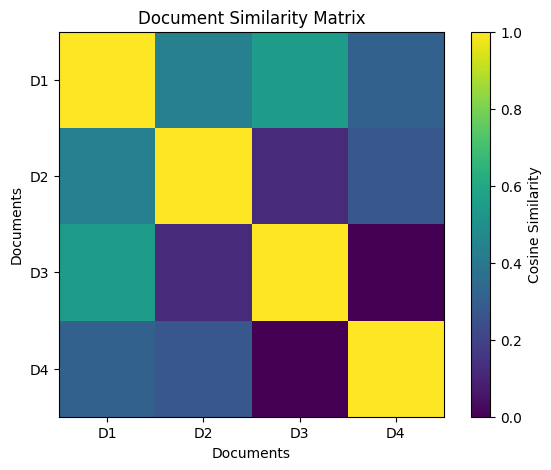

In [78]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.imshow(similarity_matrix)

plt.colorbar(label="Cosine Similarity")

plt.xticks(range(len(documents)),
           [f"D{i+1}" for i in range(len(documents))])

plt.yticks(range(len(documents)),
           [f"D{i+1}" for i in range(len(documents))])

plt.xlabel("Documents")
plt.ylabel("Documents")
plt.title("Document Similarity Matrix")

plt.show()

**1. What does a darker/lighter region indicate in your visualization?**
ANS: With the default colour map, a lighter (yellow) cell means a higher cosine similarity (the two documents are more alike) and a darker (purple) cell means a lower similarity. The colorbar on the right shows the scale.

**2. Which pair has the strongest similarity?**
ANS: D1 and D3 (0.55), apart from the diagonal.

**3. Which pair has the weakest similarity?**
ANS: D3 and D4 (0.00), because they have no common words (*learn* and *learning* are different tokens).

**4. Why is the diagonal equal to 1?**
ANS: Every document is compared with itself, so the angle between the two vectors is 0° and cos(0°) = 1, which is the maximum similarity.

# Task 22: Distance & Similarity Decision Challenge

| Situation | Choose | One-sentence justification |
|---|---|---|
| Comparing students using age and income | **Euclidean** | Both are numerical measurements, so the straight-line distance works well (after normalizing the two attributes so that income does not dominate). |
| Comparing city locations | **Euclidean** | For coordinates, the straight-line distance between two points is the natural measure (Manhattan would only be better if travel is restricted to a street grid). |
| Comparing documents | **Cosine** | Documents have different lengths, and cosine compares the direction (word usage) rather than the length of the term vectors. |
| Comparing TF-IDF vectors | **Cosine** | TF-IDF vectors are high-dimensional and sparse, and cosine similarity is the standard way to compare their direction regardless of document length. |
| Comparing binary presence/absence features | **Binary similarity** | Measures such as Jaccard or the simple matching coefficient are designed for 0/1 data, while Euclidean treats them as ordinary numbers. |
| Comparing categorical attributes | **Matching similarity** | Categories have no numeric order or magnitude, so we can only check whether the values are equal or not. |

# Task 23: Mini Data-Mining Investigation

**Chosen direction: Option C — Text Data**

**Research question:** Which two documents are most similar based on TF-IDF and cosine similarity?

**Documents:** six short documents (D1–D6) about data mining and machine/deep learning (see code).

**Method:** (1) convert the documents to TF-IDF vectors (common English stop words removed), (2) compute the cosine similarity of every pair, (3) rank the pairs and inspect the words they share.

In [79]:
docs5 = [
    "data mining finds useful patterns in large databases",                   # D1
    "data mining discovers useful knowledge from large databases",            # D2
    "machine learning builds models that learn patterns from data",           # D3
    "deep learning is a part of machine learning that uses neural networks",  # D4
    "students attend the data mining lab every week",                         # D5
    "neural networks and deep learning models need large training data"       # D6
]
names = [f"D{i+1}" for i in range(len(docs5))]

# TF-IDF + cosine similarity (stop_words removes very common words like "the", "and")
tfidf5 = TfidfVectorizer(stop_words="english").fit_transform(docs5)
sim5 = cosine_similarity(tfidf5)

pd.DataFrame(sim5, index=names, columns=names).round(3)

,D1,D2,D3,D4,D5,D6
D1,1.000,0.583,0.208,0.000,0.165,0.148
D2,0.583,1.000,0.056,0.000,0.159,0.143
D3,0.208,0.056,1.000,0.316,0.055,0.267
D4,0.000,0.000,0.316,1.000,0.000,0.517
D5,0.165,0.159,0.055,0.000,1.000,0.050
D6,0.148,0.143,0.267,0.517,0.050,1.000


In [80]:
# Find the most similar pair (ignore the diagonal)
best_score = -1
best_i = 0
best_j = 0

for i in range(len(docs5)):
    for j in range(i + 1, len(docs5)):
        if sim5[i][j] > best_score:
            best_score = sim5[i][j]
            best_i = i
            best_j = j

print("Most similar documents: D" + str(best_i + 1) + " and D" + str(best_j + 1))
print("Cosine similarity:", round(best_score, 4))
print("Shared words:", set(docs5[best_i].split()) & set(docs5[best_j].split()))

Most similar documents: D1 and D2
Cosine similarity: 0.5833
Shared words: {'large', 'databases', 'mining', 'data', 'useful'}


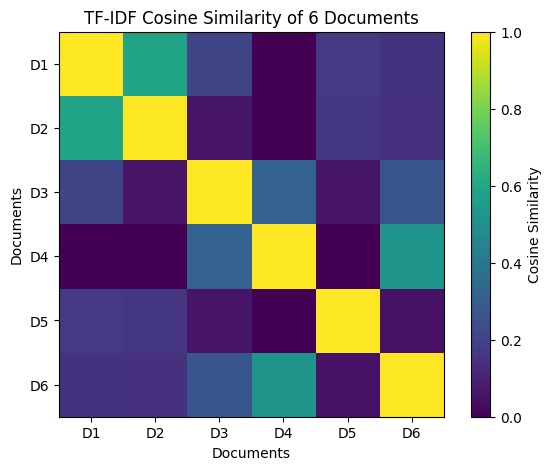

In [81]:
plt.figure(figsize=(7, 5))

plt.imshow(sim5)

plt.colorbar(label="Cosine Similarity")

plt.xticks(range(len(names)), names)
plt.yticks(range(len(names)), names)

plt.xlabel("Documents")
plt.ylabel("Documents")
plt.title("TF-IDF Cosine Similarity of 6 Documents")

plt.show()

**Results:** The most similar pair is **D1 and D2 (0.5833)**, followed by D4 and D6 (0.5169) and D3 and D4 (0.3157). D4 has a similarity of 0 with D1, D2 and D5, so D1–D4 is (one of) the least similar pairs.

**Interpretation:** D1 ("data mining finds useful patterns in large databases") and D2 ("data mining discovers useful knowledge from large databases") share five words (*data, mining, useful, large, databases*), and *large databases* are not common in the rest of the collection, so they receive a good weight. D4 and D6 are both about neural networks and deep learning. The heatmap (lighter = more similar) shows two groups: a data-mining group (D1, D2) and a deep-learning group (D3, D4, D6). D5 is only weakly related to everything, since it is short and shares only *data* and *mining* with the others.

**Conclusion:** TF-IDF with cosine similarity correctly finds the documents that talk about the same topic (D1–D2 and D4–D6). Its limitations are that it only compares exact words (no synonyms such as *finds*/*discovers*, no stemming of *learn*/*learning*), so a larger and cleaner vocabulary would give more reliable results.

# Task 24: Data-Mining Detective Challenge

In [82]:
# Case 1: raw distance vs normalized distance
age_diff = 26 - 25
income_diff = 51000 - 50000
print("Case 1 raw Euclidean distance:", np.sqrt(age_diff**2 + income_diff**2))

# min-max scaling with Age range 18-60 and Income range 10,000-200,000
age_scaled = age_diff / (60 - 18)
income_scaled = income_diff / (200000 - 10000)
print("Case 1 scaled Euclidean distance:", np.sqrt(age_scaled**2 + income_scaled**2))

# Case 2: same words, but the second document is 10 times longer
short_doc = np.array([2, 1, 0, 3])
long_doc = short_doc * 10
print("\nCase 2 Euclidean distance:", euclidean(short_doc, long_doc))
print("Case 2 cosine similarity:", cosine_similarity([short_doc], [long_doc])[0][0])

# Case 4: a word that appears in every document
print("\nCase 4 IDF = ln(4/4) =", np.log(4 / 4))

Case 1 raw Euclidean distance: 1000.000499999875
Case 1 scaled Euclidean distance: 0.02438430345655196

Case 2 Euclidean distance: 33.67491648096547
Case 2 cosine similarity: 1.0

Case 4 IDF = ln(4/4) = 0.0


**Case 1 — Age = 25, Income = 50,000 vs Age = 26, Income = 51,000: is Euclidean distance reasonable?**
ANS: Not on the raw data. The Euclidean distance is √(1² + 1000²) ≈ 1000.0005, and almost all of it comes from Income (1,000,000 compared with 1 from Age), so Age is practically ignored. Euclidean distance becomes reasonable only after normalization: with min-max scaling (Age 18–60, Income 10,000–200,000) the distance is about 0.0244, and then Age actually contributes more than Income.

**Case 2 — Two documents contain the same words, but one is much longer: would cosine similarity be useful?**
ANS: Yes. If the longer document has the same words in the same proportions, its vector points in the same direction, so the cosine similarity is 1 even though the Euclidean distance is large (33.67 in the example). Cosine similarity ignores document length.

**Case 3 — Should Euclidean distance be calculated using Student ID (1001, 1002, 1003, 1004)?**
ANS: No. Student ID is an identifier; the numbers are only labels and have no measurement meaning. Using them would suggest that students 1001 and 1002 are "closer" than 1001 and 1004 just because of the order of registration, which adds noise and misleading distances.

**Case 4 — A word appears in every document: would its IDF be high or low?**
ANS: Low. df(t) = N, so IDF = log(N/N) = log(1) = 0 (in scikit-learn's smoothed formula it is the minimum possible value, 1.0). Such a word does not help to distinguish documents, so TF-IDF gives it almost no importance.

**Case 5 — Two documents have a cosine similarity of 0.95. What does this indicate?**
ANS: The two document vectors point in almost the same direction (the angle is only about 18°), so the documents use very similar words in similar proportions and are most likely about the same topic (or are near-duplicates). It does not mean they are identical, because cosine similarity ignores length and word order.

# Short Notes (Summary)

**1. Dataset:** E-commerce customer behaviour dataset (5,000 records, 16 attributes, min-max normalized in Lab 2). Numerical attributes such as Age, Unit_Price, Quantity and Customer_Rating were used for distance calculations; Gender, City, Product_Category, Payment_Method and Device_Type were used for categorical similarity. A small 4-document (and 6-document) text collection was used for TF-IDF.

**2. Distance measures:** Euclidean (2.086), Manhattan (3.082) and Chebyshev (2.0) were computed for the same pair of customers; Manhattan ≥ Euclidean ≥ Chebyshev always holds. Before normalization the Euclidean distance was 270.36 and after normalization 2.086, which shows that attributes with large scales dominate the distance unless the data is normalized.

**3. Similarity measures:** Simple matching similarity of the two customers was 0.4. For binary data, SMC = 0.6 but Jaccard = 0.5 for the example vectors, and Jaccard is the better choice for asymmetric/sparse attributes. The cosine similarity of A = (2, 1, 0) and B = (1, 1, 1) is 0.7746 (manual and Python agree).

**4. TF-IDF analysis:** The vocabulary has 11 words. Words that occur in many documents (*data, mining, useful*) get low TF-IDF weights, and words that occur in one document (*students, discovers, knowledge, machine, learning*) get high weights.

**5. Main findings:** D1 and D3 are the most similar pair in the 4-document collection (0.5502) and D3 and D4 the least similar (0). The most similar pair is decided by the *rare* shared words, not by the common ones.

**6. Mini-investigation:** In six documents, D1 and D2 were the most similar pair (0.5833), and the heatmap clearly shows a data-mining group and a deep-learning group.

**7. Conclusion:** No distance or similarity measure is best in every situation: Euclidean/Manhattan suit normalized numeric data, matching/Jaccard suit categorical and binary data, and TF-IDF with cosine similarity suits text. Data type, scale and the meaning of absence must be considered before choosing a measure.